In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from time import perf_counter
from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin_min as nearest_centres
from threadpoolctl import threadpool_limits

seed = 42
thread_limit = threadpool_limits(limits=2)
pd.set_option('display.max_columns', None)
print('NumPy:', np.__version__, 'scikit-learn:', sklearn.__version__)

NumPy: 2.5.4 scikit-learn: 1.9.1


In [ ]:
kdd = fetch_kddcup99(subset=None, as_frame=True)
text_cols = ['protocol_type', 'service', 'flag']
data = pd.get_dummies(kdd.data, columns=text_cols, dtype=np.float32)
data = data.astype(np.float32)
drop_cols = data.columns[data.nunique() == 1].tolist()
data = data.drop(columns=drop_cols)
data = (data - data.min()) / (data.max() - data.min())
X = data.to_numpy(dtype=np.float32)
y = (kdd.target != b'normal.').to_numpy(dtype=float)
n, d = X.shape
print('Rows:', n, 'Columns:', d)
print('Dropped columns:', drop_cols)
print('Normal:', int((y == 0).sum()), 'Attack:', int(y.sum()))
del data, kdd

Rows: 494021 Columns: 116
Dropped columns: ['num_outbound_cmds', 'is_host_login']
Normal: 97278 Attack: 396743


In [ ]:
def cluster_cost(data, centres):
    nearest, distances = nearest_centres(data, centres)
    return np.sum(distances.astype(float) ** 2)

def cluster_mean(data, labels):
    return np.array([data[labels == j].mean(axis=0, dtype=float) for j in range(15)])

def count_sketch(data, target, m, rng):
    buckets = rng.integers(0, m, len(data))
    signs = rng.choice([-1, 1], len(data)).astype(np.float32)
    sx = np.zeros((m, data.shape[1]))
    sy = np.zeros(m)
    np.add.at(sx, buckets, data * signs[:, None])
    np.add.at(sy, buckets, target * signs)
    return sx, sy

In [ ]:
start = perf_counter()
base_model = KMeans(n_clusters=15, n_init=5, random_state=seed).fit(X)
base_time = perf_counter() - start
base_labels = base_model.labels_
base_cost = cluster_cost(X, base_model.cluster_centers_)
print('Q1(a) Cost:', base_cost, 'Time (s):', base_time)

Q1(a) Cost: 53883.4087360265 Time (s): 18.51095480006188


In [ ]:
rng = np.random.default_rng(seed + 1)
m_values = [5, 10, 15, 20, 25]
rows = []
for m in m_values:
    for run in range(5):
        R = rng.normal(0, 1 / np.sqrt(m), (d, m)).astype(np.float32)
        start = perf_counter()
        Y = X @ R
        model = KMeans(n_clusters=15, n_init=5, random_state=seed).fit(Y)
        run_time = perf_counter() - start
        centres = cluster_mean(X, model.labels_)
        cost = cluster_cost(X, centres)
        plus_centres = model.cluster_centers_ @ np.linalg.pinv(R)
        plus_cost = cluster_cost(X, plus_centres)
        rows.append([m, run + 1, cost, cost / base_cost, plus_cost,
                     plus_cost / base_cost, run_time])
    print('Finished Q1(b)-(d), m =', m)

q1_runs = pd.DataFrame(rows, columns=['m', 'run', 'cost', 'ratio',
                                    'plus_cost', 'plus_ratio', 'time'])
q1_table = q1_runs.groupby('m').agg(
    mean_ratio=('ratio', 'mean'), min_ratio=('ratio', 'min'),
    max_ratio=('ratio', 'max'), plus_mean=('plus_ratio', 'mean'),
    plus_min=('plus_ratio', 'min'), plus_max=('plus_ratio', 'max'),
    mean_time=('time', 'mean'))
print(q1_runs.to_string(index=False))
print('\nQ1(b)-(d) Summary\n', q1_table.to_string())

Finished Q1(b)-(d), m = 5


Finished Q1(b)-(d), m = 10


Finished Q1(b)-(d), m = 15


Finished Q1(b)-(d), m = 20


Finished Q1(b)-(d), m = 25
 m  run         cost    ratio    plus_cost  plus_ratio     time
 5    1 73481.249910 1.363708 4.137305e+06   76.782533 2.492087
 5    2 58363.074766 1.083136 4.285246e+06   79.528111 2.708093
 5    3 57510.595369 1.067315 4.208352e+06   78.101072 2.510810
 5    4 88755.216629 1.647172 4.325548e+06   80.276064 3.380753
 5    5 58598.832746 1.087512 4.105762e+06   76.197145 2.803434
10    1 54163.948800 1.005206 4.191498e+06   77.788282 3.148867
10    2 59122.745925 1.097235 4.074502e+06   75.617001 2.986407
10    3 52879.401047 0.981367 3.852718e+06   71.500998 2.837505
10    4 56175.881441 1.042545 4.056098e+06   75.275452 3.179307
10    5 56172.651077 1.042485 3.975366e+06   73.777181 2.919626
15    1 55771.059340 1.035032 3.856277e+06   71.567059 3.676054
15    2 51616.866842 0.957936 3.822020e+06   70.931296 4.008148
15    3 55733.593759 1.034337 3.608725e+06   66.972838 3.741808
15    4 55791.379756 1.035409 3.867567e+06   71.776586 3.364067
15    5 54491

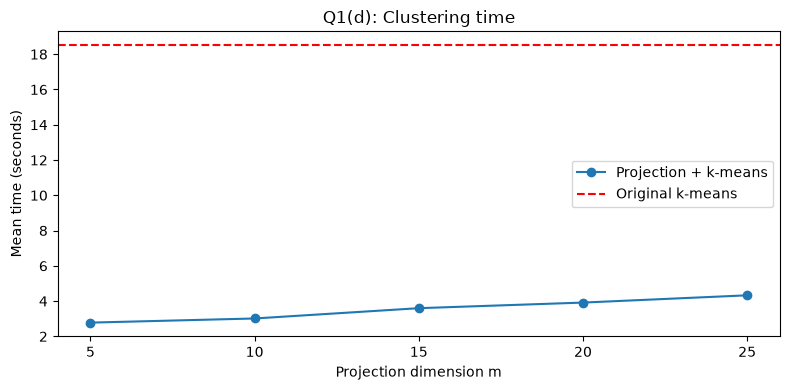

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(q1_table.index, q1_table['mean_time'], 'o-', label='Projection + k-means')
plt.axhline(base_time, color='red', linestyle='--', label='Original k-means')
plt.xlabel('Projection dimension m')
plt.ylabel('Mean time (seconds)')
plt.title('Q1(d): Clustering time')
plt.xticks(m_values)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
rng = np.random.default_rng(seed + 2)
pair_i = np.array([], dtype=int)
pair_j = np.array([], dtype=int)
zero_pairs = 0
while len(pair_i) < 10000:
    size = 10000 - len(pair_i)
    i = rng.integers(0, n, size)
    j = (i + rng.integers(1, n, size)) % n
    distances = np.sum((X[i].astype(float) - X[j]) ** 2, axis=1)
    valid = distances > 0
    zero_pairs += int((~valid).sum())
    pair_i = np.concatenate([pair_i, i[valid]])
    pair_j = np.concatenate([pair_j, j[valid]])

pair_diff = X[pair_i].astype(float) - X[pair_j]
pair_dist = np.sum(pair_diff ** 2, axis=1)
pair_ratios = []
for m in m_values:
    R = rng.normal(0, 1 / np.sqrt(m), (d, m))
    pair_ratios.append(np.sum((pair_diff @ R) ** 2, axis=1) / pair_dist)
print('Q1(e) Valid pairs:', len(pair_i), 'Zero-distance pairs redrawn:', zero_pairs)

Q1(e) Valid pairs: 10000 Zero-distance pairs redrawn: 1952


Finished Q1(e), m = 5


Finished Q1(e), m = 10


Finished Q1(e), m = 15


Finished Q1(e), m = 20


Finished Q1(e), m = 25
Fixed-partition cost: 53882.886185805866
 m  pair_mean  pair_std  part_mean  part_std
 5   0.898064  0.534744   1.021666  0.118080
10   0.699015  0.304495   0.986604  0.125161
15   1.170390  0.386031   0.979903  0.102267
20   0.934940  0.256863   0.982055  0.073918
25   0.881139  0.302541   0.995568  0.066735


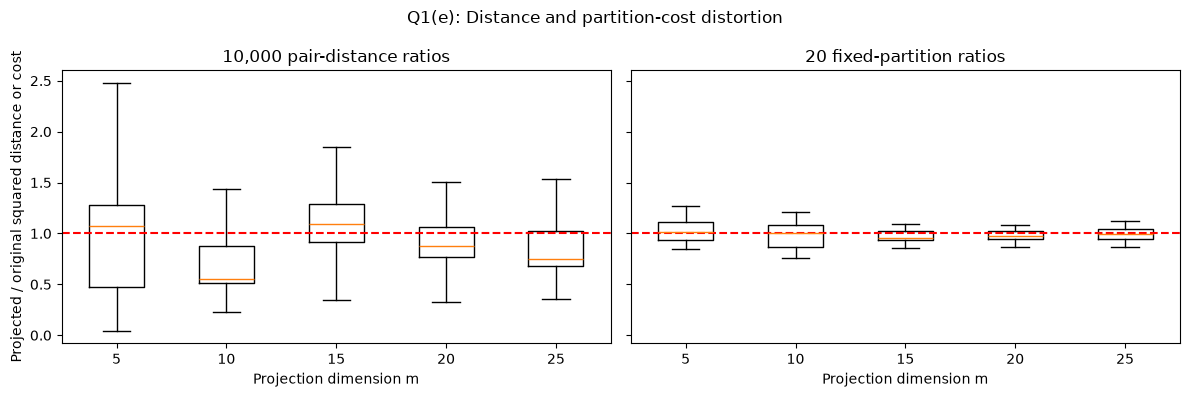

In [ ]:
rng = np.random.default_rng(seed + 3)
centres = cluster_mean(X, base_labels)
centred = X - centres[base_labels]
part_cost = np.sum(centred ** 2)
part_ratios = []
for m in m_values:
    ratios = []
    for run in range(20):
        R = rng.normal(0, 1 / np.sqrt(m), (d, m))
        ratios.append(np.sum((centred @ R) ** 2) / part_cost)
    part_ratios.append(ratios)
    print('Finished Q1(e), m =', m)

q1_spread = pd.DataFrame({
    'm': m_values,
    'pair_mean': [np.mean(a) for a in pair_ratios],
    'pair_std': [np.std(a) for a in pair_ratios],
    'part_mean': [np.mean(a) for a in part_ratios],
    'part_std': [np.std(a) for a in part_ratios]})
print('Fixed-partition cost:', part_cost)
print(q1_spread.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, values, title in zip(axes, [pair_ratios, part_ratios],
                             ['10,000 pair-distance ratios', '20 fixed-partition ratios']):
    ax.boxplot(values, tick_labels=m_values, showfliers=False)
    ax.axhline(1, color='red', linestyle='--')
    ax.set_xlabel('Projection dimension m')
    ax.set_title(title)
axes[0].set_ylabel('Projected / original squared distance or cost')
fig.suptitle('Q1(e): Distance and partition-cost distortion')
plt.tight_layout()
plt.show()
del centred, Y

In [ ]:
start = perf_counter()
b, residuals, rank, singular = np.linalg.lstsq(X, y, rcond=None)
full_time = perf_counter() - start
residual = X @ b - y
full_loss = np.sum(residual ** 2)
print('Q2(a) Loss:', full_loss, 'Time (s):', full_time)
print('Rank of X:', rank)

Q2(a) Loss: 2949.788814857172 Time (s): 5.7956023999722674
Rank of X: 113


In [ ]:
rng = np.random.default_rng(seed + 4)
sketch_sizes = [50, 100, 200, 500, 1000, 2000, 5000]
rows = []
for m in sketch_sizes:
    for run in range(5):
        start = perf_counter()
        sx, sy = count_sketch(X, y, m, rng)
        a = np.linalg.lstsq(sx, sy, rcond=None)[0]
        run_time = perf_counter() - start
        loss = np.sum((X @ a - y) ** 2)
        sketch_loss = np.sum((sx @ a - sy) ** 2)
        rows.append([m, run + 1, loss, loss / full_loss, sketch_loss, run_time])
    print('Finished Q2(b)-(c), m =', m)

q2_runs = pd.DataFrame(rows, columns=['m', 'run', 'loss', 'ratio', 'sketch_loss', 'time'])
q2_table = q2_runs.groupby('m').agg(
    mean_ratio=('ratio', 'mean'), min_ratio=('ratio', 'min'),
    max_ratio=('ratio', 'max'), mean_sketch=('sketch_loss', 'mean'),
    mean_time=('time', 'mean'))
print(q2_runs.to_string(index=False))
print('\nQ2(b)-(c) Summary\n', q2_table.to_string())

Finished Q2(b)-(c), m = 50


Finished Q2(b)-(c), m = 100


Finished Q2(b)-(c), m = 200


Finished Q2(b)-(c), m = 500


Finished Q2(b)-(c), m = 1000


Finished Q2(b)-(c), m = 2000


Finished Q2(b)-(c), m = 5000
   m  run          loss     ratio  sketch_loss     time
  50    1   9333.997337  3.164293 8.239652e-25 4.011082
  50    2  10720.094595  3.634191 3.903943e-24 4.054387
  50    3  12139.663310  4.115435 1.451914e-24 4.104545
  50    4   9916.206551  3.361667 1.792838e-24 4.066367
  50    5   8485.081942  2.876505 8.613241e-25 3.988271
 100    1  44963.186806 15.242849 6.294400e-23 4.414159
 100    2  44285.896818 15.013243 4.122268e-23 4.542203
 100    3  35711.597995 12.106493 3.146442e-23 4.137601
 100    4  63636.800028 21.573341 3.147765e-23 4.135804
 100    5 108622.871857 36.823949 7.537130e-24 4.736090
 200    1   8700.559827  2.949553 1.234275e+03 4.032243
 200    2   8529.472106  2.891553 1.206021e+03 3.973524
 200    3   7345.602562  2.490213 1.170326e+03 4.073645
 200    4   5750.296400  1.949393 1.362684e+03 3.879372
 200    5   6639.411066  2.250809 1.215565e+03 4.119671
 500    1  33927.314259 11.501608 2.173400e+03 3.765972
 500    2   3826.20

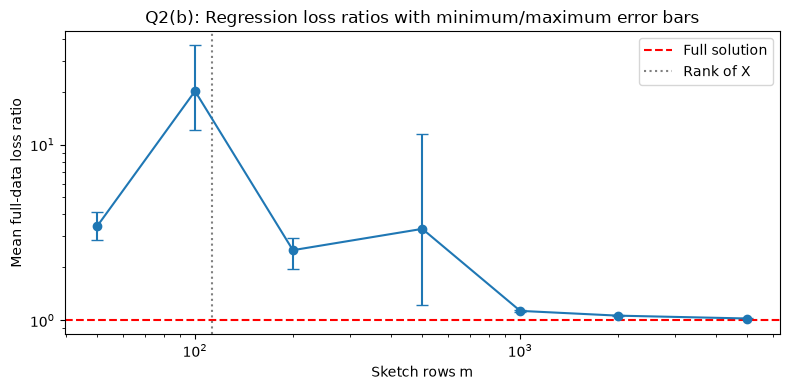

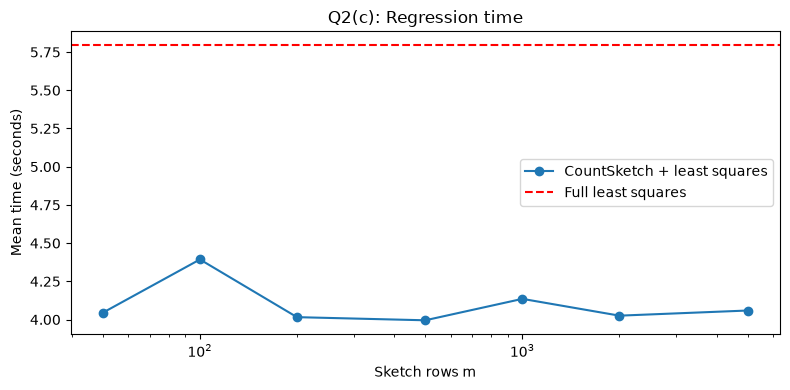

In [ ]:
errors = np.array([q2_table['mean_ratio'] - q2_table['min_ratio'],
                   q2_table['max_ratio'] - q2_table['mean_ratio']])
plt.figure(figsize=(8, 4))
plt.errorbar(sketch_sizes, q2_table['mean_ratio'], yerr=errors, fmt='o-', capsize=4)
plt.axhline(1, color='red', linestyle='--', label='Full solution')
plt.axvline(rank, color='grey', linestyle=':', label='Rank of X')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Sketch rows m')
plt.ylabel('Mean full-data loss ratio')
plt.title('Q2(b): Regression loss ratios with minimum/maximum error bars')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(sketch_sizes, q2_table['mean_time'], 'o-', label='CountSketch + least squares')
plt.axhline(full_time, color='red', linestyle='--', label='Full least squares')
plt.xscale('log')
plt.xlabel('Sketch rows m')
plt.ylabel('Mean time (seconds)')
plt.title('Q2(c): Regression time')
plt.legend()
plt.tight_layout()
plt.show()

Q2(d) Population standard deviations
    m     mean      std
  50 1.009367 0.189922
 500 1.004002 0.065227
5000 0.999332 0.022547


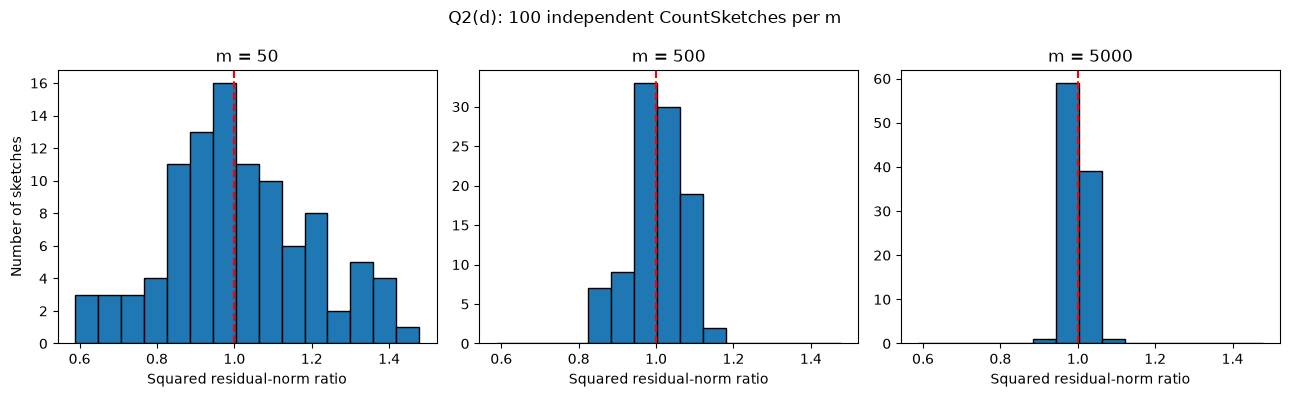

In [ ]:
rng = np.random.default_rng(seed + 5)
res_sizes = [50, 500, 5000]
res_ratios = []
for m in res_sizes:
    ratios = []
    for run in range(100):
        buckets = rng.integers(0, m, n)
        signs = rng.choice([-1, 1], n)
        sv = np.zeros(m)
        np.add.at(sv, buckets, residual * signs)
        ratios.append(np.sum(sv ** 2) / full_loss)
    res_ratios.append(ratios)

q2_residual = pd.DataFrame({
    'm': res_sizes, 'mean': [np.mean(a) for a in res_ratios],
    'std': [np.std(a) for a in res_ratios]})
print('Q2(d) Population standard deviations\n', q2_residual.to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True)
bins = np.linspace(min(min(a) for a in res_ratios), max(max(a) for a in res_ratios), 16)
for ax, m, ratios in zip(axes, res_sizes, res_ratios):
    ax.hist(ratios, bins=bins, edgecolor='black')
    ax.axvline(1, color='red', linestyle='--')
    ax.set_title('m = ' + str(m))
    ax.set_xlabel('Squared residual-norm ratio')
axes[0].set_ylabel('Number of sketches')
fig.suptitle('Q2(d): 100 independent CountSketches per m')
plt.tight_layout()
plt.show()

In [ ]:
rng = np.random.default_rng(seed + 6)
subset = rng.choice(n, 50000, replace=False)
small_x = X[subset]
small_y = y[subset]
small_b = np.linalg.lstsq(small_x, small_y, rcond=None)[0]
small_loss = np.sum((small_x @ small_b - small_y) ** 2)
rng = np.random.default_rng(seed + 7)
m = 500
rows = []
for method in ['CountSketch', 'Gaussian']:
    for run in range(5):
        start = perf_counter()
        if method == 'CountSketch':
            sx, sy = count_sketch(small_x, small_y, m, rng)
        else:
            S = rng.normal(0, 1 / np.sqrt(m), (m, len(small_x)))
            sx = S @ small_x
            sy = S @ small_y
        sketch_time = perf_counter() - start
        a = np.linalg.lstsq(sx, sy, rcond=None)[0]
        loss = np.sum((small_x @ a - small_y) ** 2)
        rows.append([method, run + 1, sketch_time, loss, loss / small_loss])
        if method == 'Gaussian':
            del S

q2_compare = pd.DataFrame(rows, columns=['method', 'run', 'time', 'loss', 'ratio'])
q2_methods = q2_compare.groupby('method').agg(
    mean_time=('time', 'mean'), mean_ratio=('ratio', 'mean'))
print('Q2(e) Subset rows:', len(subset), 'Subset baseline loss:', small_loss)
print(q2_compare.to_string(index=False))
print('\nQ2(e) Summary\n', q2_methods.to_string())

Q2(e) Subset rows: 50000 Subset baseline loss: 265.41038046314384
     method  run     time       loss    ratio
CountSketch    1 0.412470 320.056450 1.205893
CountSketch    2 0.484456 357.804292 1.348117
CountSketch    3 0.398340 358.199376 1.349606
CountSketch    4 0.374566 332.302853 1.252034
CountSketch    5 0.346595 330.708733 1.246028
   Gaussian    1 0.443758 333.571655 1.256815
   Gaussian    2 0.432996 361.328048 1.361394
   Gaussian    3 0.382313 340.803401 1.284062
   Gaussian    4 0.394768 350.594457 1.320952
   Gaussian    5 0.423494 338.989898 1.277229

Q2(e) Summary
              mean_time  mean_ratio
method                            
CountSketch   0.403285    1.280336
Gaussian      0.415466    1.300090
